# 03 — XGBoost + scale_pos_weight + TreeSHAP (2 kelas biner)

**Notebook utama project ini. Menggantikan notebook lama 03 / 04 / 05.**

Notebook lama 03 (RF), 04 (RF+SMOTE), 05 (evaluasi) sudah diarsipkan ke `notebooks/archive/` — **tidak perlu di-run lagi**. Angkanya dipakai sebagai baseline di tabel bawah (dari skripsi, terverifikasi dari output notebook lama):

| Model (skripsi, 3 kelas) | Accuracy | Balanced Acc. | Precision | Recall | F1 | ROC-AUC |
|---|---:|---:|---:|---:|---:|---:|
| RF | 0.8744 | 0.5982 | 0.7351 | 0.5982 | 0.6384 | 0.9193 |
| RF + SMOTE | 0.8092 | 0.7343 | 0.6163 | 0.7343 | 0.6520 | 0.9065 |

**Model FINAL (diputuskan 2026-11-18 22:38): XGBoost + scale_pos_weight** — CV 5-fold membuktikan lebih baik dari SMOTE-NC (BalAcc 0,8210 vs 0,7741, Recall 0,8496 vs 0,7431, ROC-AUC 0,9046 vs 0,8743). SMOTE-NC tetap diuji sebagai pembanding, bukan model final.

**Yang baru di sini:** target biner, XGBoost, perbandingan SMOTE-NC vs scale_pos_weight, RobustScaler, imputasi di dalam fold, threshold tuning, dan TreeSHAP.

**Aturan anti-leakage (wajib):** di dalam tiap fold, fit imputasi + scaler + encoder HANYA di train, SMOTE-NC HANYA di train (untuk pembanding), evaluasi HANYA di test asli (bukan sintetik).


In [11]:
import pandas as pd, numpy as np, joblib
import matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import RobustScaler, OrdinalEncoder, OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, confusion_matrix, classification_report
from imblearn.over_sampling import SMOTENC
from xgboost import XGBClassifier

pd.options.display.float_format = '{:.4f}'.format
OUT_FIG = Path('../outputs/figures'); OUT_TAB = Path('../outputs/tables'); OUT_SHAP = Path('../outputs/shap')
for p in [OUT_FIG, OUT_TAB, OUT_SHAP]: p.mkdir(parents=True, exist_ok=True)
print('ok')

ok


In [12]:
df = pd.read_csv('../data/processed/inventaris_for_model.csv')
print('shape:', df.shape)
print(df['kondisi_biner'].value_counts().to_dict(), '| rasio:', 1889/412)
display(df.head())

shape: (2301, 10)
{0: 1889, 1: 412} | rasio: 4.584951456310679


,triwulan,nama_ruangan,nama_barang,bahan,kategori,umur,harga_per_unit,depresiasi_aset,kondisi_asli,kondisi_biner
0,Q1,Adenium,Lemari Sepatu Dua Pintu,Kayu,Furnitur,11,2400000.0000,2400000.0000,Baik,0
1,Q1,Adenium,Printer Canon 237,Besi,Elektronik,11,1350000.0000,1345102.2400,Baik,0
2,Q1,Adenium,Kursi Roda Spirit BM,Besi,Pelengkap,11,1149500.0000,1149500.0000,Baik,0
3,Q1,Adenium,Lemari Sliding Kaca,Besi,Furnitur,10,3245000.0000,3245000.0000,Baik,0
4,Q1,Adenium,Meja Nurse Station,Besi,Furnitur,10,5875000.0000,5875000.0000,Baik,0


In [13]:
# --- Helper: depresiasi (sama seperti notebook 02) ---
def hitung_depresiasi(umur, harga_per_unit, kategori):
    if pd.isna(harga_per_unit): return np.nan
    if kategori == 'Elektronik':
        nb = harga_per_unit
        for _ in range(int(umur)): nb -= nb * (2/5)
        return round(min(harga_per_unit - nb, harga_per_unit), 2)
    return round(min((harga_per_unit/10)*umur, harga_per_unit), 2)

def imputasi_harga(train, test):
    """Isi harga_per_unit yang kosong HANYA dari statistik TRAIN."""
    tr, te = train.copy(), test.copy()
    nama_mean = tr.groupby('nama_barang')['harga_per_unit'].mean()
    grup_mean = tr.groupby(['bahan','kategori'])['harga_per_unit'].mean()
    med = tr['harga_per_unit'].median()
    for d in (tr, te):
        d['harga_per_unit'] = d['harga_per_unit'].fillna(d['nama_barang'].map(nama_mean))
        # isi sisa dengan mean bahan+kategori (pakai map per baris)
        mask = d['harga_per_unit'].isna()
        if mask.any():
            keys = list(zip(d.loc[mask,'bahan'], d.loc[mask,'kategori']))
            d.loc[mask,'harga_per_unit'] = [grup_mean.get(k, np.nan) for k in keys]
        d['harga_per_unit'] = d['harga_per_unit'].fillna(med)
    return tr, te

In [14]:
# --- Helper: transformasi train/test dalam satu fold ---
NUM = ['umur','harga_per_unit','depresiasi_aset']; CAT = ['bahan','kategori']
def transform_fold(train_raw, test_raw):
    tr, te = imputasi_harga(train_raw, test_raw)
    for d in (tr, te):
        d['depresiasi_aset'] = [hitung_depresiasi(r['umur'], r['harga_per_unit'], r['kategori']) for _, r in d.iterrows()]
    scaler = RobustScaler(); enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
    Xtr_num = scaler.fit_transform(tr[NUM]); Xte_num = scaler.transform(te[NUM])
    Xtr_cat = enc.fit_transform(tr[CAT]); Xte_cat = enc.transform(te[CAT])
    Xtr = np.hstack([Xtr_cat, Xtr_num]); Xte = np.hstack([Xte_cat, Xte_num])
    return Xtr, Xte, scaler, enc

def onehot_after(Xtr_res, Xte, Xtr_cat_orig):
    ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
    ohe.fit(Xtr_cat_orig)
    Xtr_f = np.hstack([ohe.transform(Xtr_res[:, :2]), Xtr_res[:, 2:]])
    Xte_f = np.hstack([ohe.transform(Xte[:, :2]), Xte[:, 2:]])
    return Xtr_f, Xte_f, ohe

In [15]:
# --- CV: 3 model di preprocessing yang SAMA per fold ---
# M1 = RF + SMOTE-NC (pembanding biner yang adil)
# M2 = XGBoost + SMOTE-NC (pembanding)
# M3 = XGBoost + scale_pos_weight, TANPA SMOTE-NC (MODEL FINAL)
X_all = df.copy(); y_all = df['kondisi_biner'].values
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows, oof = [], {'y_true': [], 'y_proba_xgb_smotenc': [], 'y_proba_xgb_spw': []}
for fold, (tr_idx, te_idx) in enumerate(skf.split(X_all, y_all), start=1):
    train_raw, test_raw = X_all.iloc[tr_idx], X_all.iloc[te_idx]
    Xtr, Xte, scaler, enc = transform_fold(train_raw, test_raw)
    ytr, yte = y_all[tr_idx], y_all[te_idx]
    sm = SMOTENC(categorical_features=[0,1], k_neighbors=5, random_state=42)
    Xtr_res, ytr_res = sm.fit_resample(Xtr, ytr)
    Xtr_f, Xte_f, ohe = onehot_after(Xtr_res, Xte, Xtr[:, :2])
    # M1 + M2 di data resample; M3 di data asli (tapi sudah di-one-hot)
    Xtr_nosm, Xte_nosm, _ = onehot_after(Xtr, Xte, Xtr[:, :2])
    models = {
        'RF + SMOTE-NC': RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
        'XGB + SMOTE-NC': XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, eval_metric='logloss', random_state=42, n_jobs=-1),
        'XGB + scale_pos_weight': XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, eval_metric='logloss', random_state=42, n_jobs=-1, scale_pos_weight=float((ytr==0).sum()/(ytr==1).sum())),
    }
    fits = {'RF + SMOTE-NC': (Xtr_f, ytr_res), 'XGB + SMOTE-NC': (Xtr_f, ytr_res), 'XGB + scale_pos_weight': (Xtr_nosm, ytr)}
    for name, m in models.items():
        Xf, yf = fits[name]
        m.fit(Xf, yf)
        proba = m.predict_proba(Xte_f if 'SMOTE-NC' in name else Xte_nosm)[:, 1]
        pred = (proba > 0.5).astype(int)
        rows.append({'fold': fold, 'model': name, 'accuracy': accuracy_score(yte, pred), 'balanced_accuracy': balanced_accuracy_score(yte, pred), 'precision': precision_score(yte, pred, zero_division=0), 'recall': recall_score(yte, pred, zero_division=0), 'f1': f1_score(yte, pred, zero_division=0), 'roc_auc': roc_auc_score(yte, proba), 'pr_auc': average_precision_score(yte, proba)})
        if name == 'XGB + SMOTE-NC':
            oof['y_true'].extend(yte.tolist()); oof['y_proba_xgb_smotenc'].extend(proba.tolist())
        if name == 'XGB + scale_pos_weight':
            oof['y_proba_xgb_spw'].extend(proba.tolist())
    print(f'fold {fold} selesai')
res = pd.DataFrame(rows)
display(res.groupby('model').mean(numeric_only=True).round(4))
display(res.groupby('model').std(numeric_only=True).round(4))
res.to_csv(OUT_TAB/'perbandingan_model_cv.csv', index=False)
print('saved perbandingan_model_cv.csv')

fold 1 selesai
fold 2 selesai
fold 3 selesai
fold 4 selesai
fold 5 selesai


,fold,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,,,
RF + SMOTE-NC,3.0000,0.8171,0.7909,0.4973,0.7502,0.5960,0.9036,0.7122
XGB + SMOTE-NC,3.0000,0.7940,0.7741,0.4558,0.7431,0.5643,0.8743,0.6564
XGB + scale_pos_weight,3.0000,0.8027,0.8210,0.4733,0.8496,0.6074,0.9046,0.7012


,fold,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,pr_auc
model,,,,,,,,
RF + SMOTE-NC,1.5811,0.0271,0.0270,0.0507,0.0574,0.0379,0.0186,0.0602
XGB + SMOTE-NC,1.5811,0.0310,0.0442,0.0497,0.0749,0.0548,0.0330,0.0739
XGB + scale_pos_weight,1.5811,0.0257,0.0297,0.0382,0.0462,0.0388,0.0216,0.0759


saved perbandingan_model_cv.csv


In [16]:
# --- Threshold tuning untuk model FINAL: XGB + scale_pos_weight (OOF) ---
# SMOTE-NC dihitung juga sebagai pembanding, tapi thr_f2 yang disimpan adalah milik SPW.
from sklearn.metrics import precision_recall_curve
y_true = np.array(oof['y_true']); y_proba = np.array(oof['y_proba_xgb_spw']); y_proba_smotenc = np.array(oof['y_proba_xgb_smotenc'])
prec, rec, thr = precision_recall_curve(y_true, y_proba)
f2 = 5*prec*rec/(4*prec+rec+1e-9)
best_idx = int(np.argmax(f2[:-1])); thr_f2 = float(thr[best_idx])
# Youden J dari ROC
from sklearn.metrics import roc_curve
fpr, tpr, thr_roc = roc_curve(y_true, y_proba)
youden_idx = int(np.argmax(tpr-fpr)); thr_youden = float(thr_roc[youden_idx])
print(f'threshold default 0.50 | F2-optimal {thr_f2:.3f} (F2={f2[best_idx]:.3f}) | Youden {thr_youden:.3f}')
for t in [0.5, thr_f2, thr_youden]:
    p = (y_proba > t).astype(int)
    print(f"thr {t:.3f}: acc {accuracy_score(y_true,p):.4f} bal_acc {balanced_accuracy_score(y_true,p):.4f} prec {precision_score(y_true,p,zero_division=0):.4f} rec {recall_score(y_true,p,zero_division=0):.4f} f1 {f1_score(y_true,p,zero_division=0):.4f}")
print(f'Pembanding SMOTE-NC di thr 0.5: bal_acc {balanced_accuracy_score(y_true, (y_proba_smotenc>0.5).astype(int)):.4f} rec {recall_score(y_true, (y_proba_smotenc>0.5).astype(int)):.4f}')
print('\nRekomendasi: untuk RS, False Negative (rusak ketebak Baik) lebih mahal — pilih threshold F2/Youden SPW di atas, bukan 0.5 buta, dan laporkan keduanya.')

threshold default 0.50 | F2-optimal 0.417 (F2=0.746) | Youden 0.440
thr 0.500: acc 0.8027 bal_acc 0.8210 prec 0.4717 rec 0.8495 f1 0.6066
thr 0.417: acc 0.7757 bal_acc 0.8245 prec 0.4385 rec 0.9005 f1 0.5898
thr 0.440: acc 0.7923 bal_acc 0.8241 prec 0.4580 rec 0.8738 f1 0.6010
Pembanding SMOTE-NC di thr 0.5: bal_acc 0.7740 rec 0.7427

Rekomendasi: untuk RS, False Negative (rusak ketebak Baik) lebih mahal — pilih threshold F2/Youden SPW di atas, bukan 0.5 buta, dan laporkan keduanya.


                    precision    recall  f1-score   support

              Baik       0.96      0.79      0.87      1889
Perlu Pemeliharaan       0.47      0.85      0.61       412

          accuracy                           0.80      2301
         macro avg       0.72      0.82      0.74      2301
      weighted avg       0.87      0.80      0.82      2301



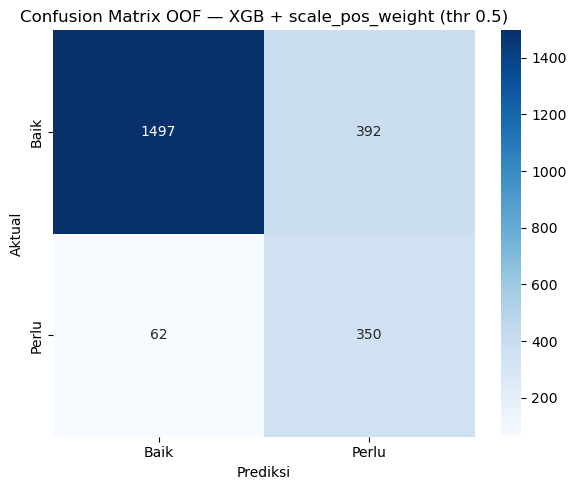

In [17]:
# --- Confusion matrix model FINAL (XGB + scale_pos_weight, OOF, threshold 0.5) ---
pred05 = (y_proba > 0.5).astype(int)
print(classification_report(y_true, pred05, target_names=['Baik','Perlu Pemeliharaan']))
cm = confusion_matrix(y_true, pred05)
plt.figure(figsize=(6,5)); sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Baik','Perlu'], yticklabels=['Baik','Perlu'])
plt.title('Confusion Matrix OOF — XGB + scale_pos_weight (thr 0.5)'); plt.xlabel('Prediksi'); plt.ylabel('Aktual'); plt.tight_layout(); plt.savefig(OUT_FIG/'cm_xgb_spw.png', dpi=150); plt.show()

In [18]:
# --- Final fit di FULL data + simpan model FINAL: XGB + scale_pos_weight ---
# TIDAK pakai SMOTE-NC di final fit (diputuskan 2026-11-18): data asli saja,
# imbalance ditangani dengan scale_pos_weight = 1889/412 = 4.59 di loss function.
# Ini juga yang dipakai FastAPI nanti — tidak ada langkah SMOTE saat prediksi.
tr_full = df.copy()
# imputasi full-data HANYA untuk final model (sudah tidak ada test di tahap ini)
tr_full, _ = imputasi_harga(tr_full, tr_full.copy())
tr_full['depresiasi_aset'] = [hitung_depresiasi(r['umur'], r['harga_per_unit'], r['kategori']) for _, r in tr_full.iterrows()]
scaler = RobustScaler(); enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
X_num = scaler.fit_transform(tr_full[NUM]); X_cat = enc.fit_transform(tr_full[CAT])
X_full = np.hstack([X_cat, X_num]); y_full = tr_full['kondisi_biner'].values
spw = float((y_full==0).sum()/(y_full==1).sum())
ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False); ohe.fit(X_cat)
X_final = np.hstack([ohe.transform(X_cat), X_num])
final_model = XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, eval_metric='logloss', random_state=42, n_jobs=-1, scale_pos_weight=spw)
final_model.fit(X_final, y_full)
bundle = {'scaler': scaler, 'encoder': enc, 'onehot': ohe, 'model': final_model, 'model_name': 'XGB + scale_pos_weight', 'scale_pos_weight': spw, 'threshold_default': 0.5, 'threshold_f2': thr_f2, 'threshold_youden': thr_youden, 'num_cols': NUM, 'cat_cols': CAT, 'reference_year': 2025}
joblib.dump(bundle, '../models/xgb_scaleposweight_binary.pkl')
print(f'saved ../models/xgb_scaleposweight_binary.pkl | scale_pos_weight={spw:.2f} | thr_f2={thr_f2:.3f} | train:', X_final.shape, np.bincount(y_full))


saved ../models/xgb_scaleposweight_binary.pkl | scale_pos_weight=4.58 | thr_f2=0.417 | train: (2301, 11) [1889  412]


SHAP shape: (500, 11) | fitur: 11


,fitur,mean_abs_shap
3,harga_per_unit,1.1071
2,umur,0.7022
4,depresiasi_aset,0.6543
0,bahan,0.2821
1,kategori,0.2600


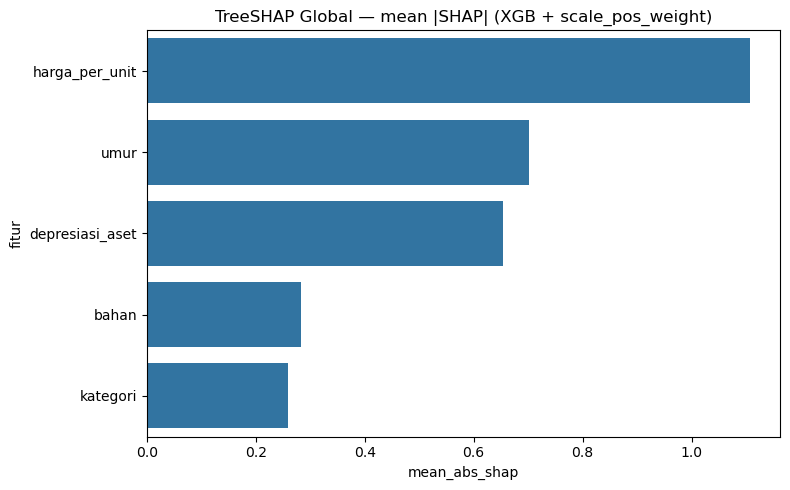

In [19]:
# --- TreeSHAP: global + lokal (di data ASLI, bukan sintetik) ---
import shap
# Transform full data ASLI (tanpa SMOTE) dengan preprocessor final
X_num_o = scaler.transform(tr_full[NUM]); X_cat_o = enc.transform(tr_full[CAT])
X_ohe = np.hstack([ohe.transform(X_cat_o), X_num_o])
# Nama fitur One-Hot dari kategori ASLI (bukan kode 0.0/1.0 dari OrdinalEncoder)
feature_names = [f'{col}_{cat}' for col, cats in zip(CAT, enc.categories_) for cat in cats] + NUM
# Ambil subset 500 baris untuk kecepatan plot (SHAP Tree cepat, tapi beeswarm 2301 baris berat)
idx = np.random.RandomState(42).choice(len(X_ohe), size=min(500, len(X_ohe)), replace=False)
explainer = shap.TreeExplainer(final_model)
sv = explainer.shap_values(X_ohe[idx])
if isinstance(sv, list): sv = sv[1]
if sv.ndim == 3: sv = sv[:, :, 1]
print('SHAP shape:', sv.shape, '| fitur:', len(feature_names))
# Agregasi One-Hot kembali ke 5 fitur asli (seperti notebook 05 cell 10)
import pandas as pd
shap_df = pd.DataFrame(np.abs(sv), columns=feature_names)
shap_df['bahan'] = shap_df[[c for c in feature_names if c.startswith('bahan')]].sum(axis=1) if any(c.startswith('bahan') for c in feature_names) else 0
shap_df['kategori'] = shap_df[[c for c in feature_names if c.startswith('kategori')]].sum(axis=1) if any(c.startswith('kategori') for c in feature_names) else 0
agg = pd.DataFrame({'fitur': ['bahan','kategori','umur','harga_per_unit','depresiasi_aset'], 'mean_abs_shap': [shap_df['bahan'].mean(), shap_df['kategori'].mean(), shap_df['umur'].mean() if 'umur' in shap_df else 0, shap_df['harga_per_unit'].mean() if 'harga_per_unit' in shap_df else 0, shap_df['depresiasi_aset'].mean() if 'depresiasi_aset' in shap_df else 0]}).sort_values('mean_abs_shap', ascending=False)
display(agg)
agg.to_csv(OUT_TAB/'shap_global.csv', index=False)
plt.figure(figsize=(8,5)); sns.barplot(data=agg, x='mean_abs_shap', y='fitur'); plt.title('TreeSHAP Global — mean |SHAP| (XGB + scale_pos_weight)'); plt.tight_layout(); plt.savefig(OUT_SHAP/'shap_global_bar.png', dpi=150); plt.show()

In [20]:
# --- SHAP lokal: 1 contoh Perlu Pemeliharaan + cetak Top-3 alasan ---
# Pilih 1 baris test asli dengan probabilitas tinggi
proba_full = final_model.predict_proba(X_ohe)[:, 1]
idx_high = int(np.argmax(proba_full))
print('Contoh probabilitas tertinggi Perlu Pemeliharaan:')
print(tr_full.iloc[idx_high][['nama_barang','bahan','kategori','umur','harga_per_unit','depresiasi_aset','kondisi_asli']].to_dict())
print('proba:', round(float(proba_full[idx_high]), 3))
# SHAP untuk baris itu (pakai explainer yang sama, hitung ulang 1 baris)
sv_one = explainer.shap_values(X_ohe[idx_high:idx_high+1])
if isinstance(sv_one, list): sv_one = sv_one[1]
if sv_one.ndim == 3: sv_one = sv_one[:, :, 1]
order = np.argsort(-np.abs(sv_one[0]))[:3]
for j in order:
    print(f"  {feature_names[j]}: SHAP {sv_one[0][j]:+.3f} (nilai: {X_ohe[idx_high, j]:.3f})")
print('\nGunakan tabel ini di Web/Android sebagai kalimat: Diprediksi Perlu Pemeliharaan karena [Top-1], [Top-2], [Top-3].')

Contoh probabilitas tertinggi Perlu Pemeliharaan:
{'nama_barang': 'Satir', 'bahan': 'Kain', 'kategori': 'Pelengkap', 'umur': 12, 'harga_per_unit': 1850031.25, 'depresiasi_aset': 1850031.25, 'kondisi_asli': 'Kurang Baik'}
proba: 0.996
  umur: SHAP +2.897 (nilai: 1.000)
  bahan_Kain: SHAP +2.709 (nilai: 1.000)
  harga_per_unit: SHAP -0.487 (nilai: -0.569)

Gunakan tabel ini di Web/Android sebagai kalimat: Diprediksi Perlu Pemeliharaan karena [Top-1], [Top-2], [Top-3].


## Kesimpulan 03

- Isi tabel perbandingan di `outputs/tables/perbandingan_model_cv.csv` ke laporan — JANGAN bandingkan Accuracy 3 kelas vs 2 kelas langsung.
- **Model final: XGBoost + scale_pos_weight** (BalAcc CV 0,8210, ROC-AUC 0,9046, Recall 0,8496 di thr 0,5; threshold F2/Youden dihitung ulang untuk SPW di notebook ini). Tersimpan di `models/xgb_scaleposweight_binary.pkl` (scaler + encoder + one-hot + XGBoost + scale_pos_weight 4,59 + threshold F2 SPW).
- File lama `models/xgb_smotenc_binary.pkl` tidak lagi dipakai sebagai model final — SMOTE-NC hanya pembanding di CV. Threshold lama 0,378 itu milik SMOTE-NC, JANGAN dipakai untuk model SPW.
- SHAP global di `outputs/shap/shap_global_bar.png`, tabel di `outputs/tables/shap_global.csv`.
- Langkah berikut: run notebook 04 (evaluasi, baca bundle SPW baru), lalu FastAPI yang memuat bundle ini + Supabase (tabel inventories / predictions / maintenance_tasks) + Web Vue + Android Flutter.
